In [228]:
!pip install fitter


In [229]:
from google.colab import drive
import pandas as pd
import numpy as np
import random
from io import StringIO
import matplotlib.pyplot as plt
from fitter import Fitter
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Conecta ao Google Drive e ajusta a exibição
drive.mount('/content/drive')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.expand_frame_repr', False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [230]:
df = pd.read_csv('/content/drive/MyDrive/ENEM_2019/NewDatasetENEM2019.csv', sep=';')

In [231]:
#display(df)
y = df['NU_NOTA_MT']

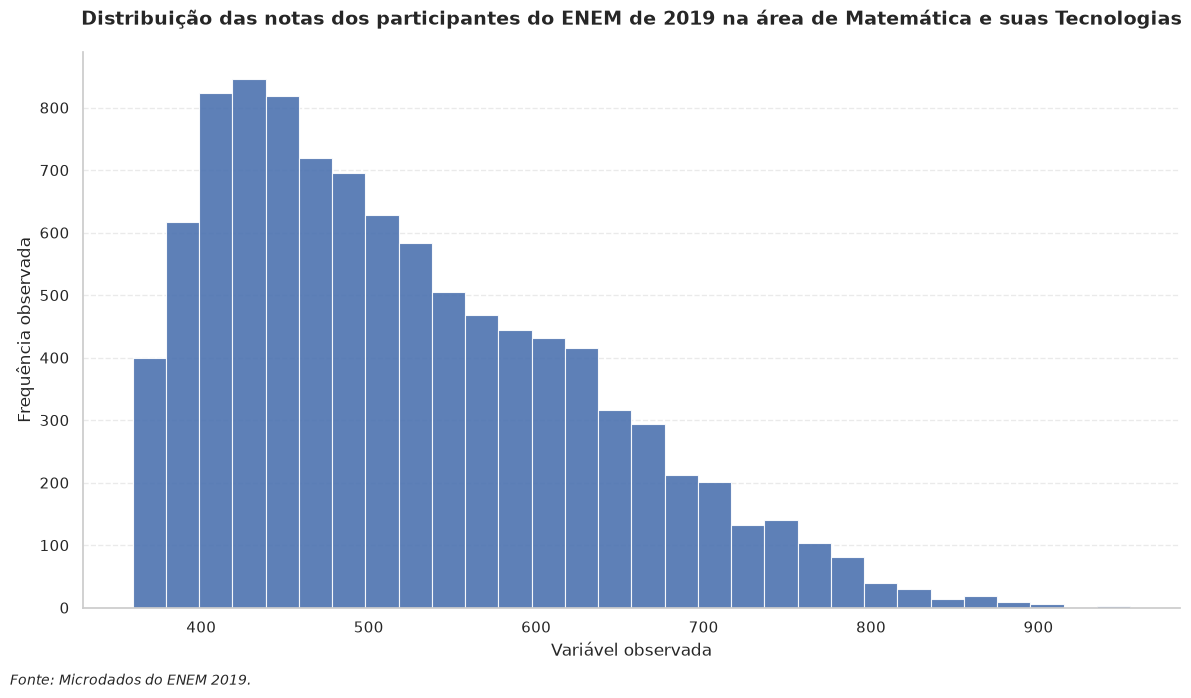

In [232]:
# Frequência observada de cada nota
# Remover valores ausentes
notas = df['NU_NOTA_MT']

# Configuração estética
sns.set_theme(style="whitegrid")

# Criar figura
fig, ax = plt.subplots(figsize=(12, 7))

# Histograma de frequências
ax.hist(
    notas,
    bins=30,
    color="#4C72B0",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9
)

# Título
ax.set_title(
    "Distribuição das notas dos participantes do "
    "ENEM de 2019 na área de Matemática e suas Tecnologias",
    fontsize=14,
    fontweight="bold",
    pad=20
)

# Nome dos eixos
ax.set_xlabel("Variável observada", fontsize=12)
ax.set_ylabel("Frequência observada", fontsize=12)

# Ajustes estéticos
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.grid(axis="x", visible=False)

sns.despine()

# Fonte dos dados
fig.text(
    0.01,
    0.01,
    "Fonte: Microdados do ENEM 2019.",
    fontsize=10,
    style="italic"
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.12)

plt.show()

In [233]:
#f = Fitter(y)



#f.fit()      # O ajuste pode demorar um pouco, pois testa muitas distribuições
#f.summary()  # Mostra um ranking das melhores distribuições

#plt.hist(y)
#print(min(y))
df.drop(["NU_INSCRICAO",'NU_NOTA_CN',	'NU_NOTA_CH',	'NU_NOTA_LC',	'NU_NOTA_MT','NU_NOTA_REDACAO' ], inplace=True , axis=1)
#print(df.dtype, np.isnan(df).sum())

print(f"Total carregado: {df.shape[0]} linhas e {df.shape[1]} colunas.")



Total carregado: 10000 linhas e 27 colunas.


/tmp/ipykernel_11503/4159768454.py:10: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(["NU_INSCRICAO",'NU_NOTA_CN',	'NU_NOTA_CH',	'NU_NOTA_LC',	'NU_NOTA_MT','NU_NOTA_REDACAO' ], inplace=True , axis=1)


In [264]:
from sklearn.linear_model import TweedieRegressor

glm = TweedieRegressor(verbose= True)

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error


x_train , x_test , y_train , y_test = train_test_split(df,y , random_state = 0)

In [265]:
glm.fit(x_train,y_train)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_glm/glm.py:285: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res)


TweedieRegressor(verbose=True)

In [266]:
from GLM import MLGBase
glm = MLGBase(verbose=True,dist="gamma")
glm.fit(x_train,y_train)


Modelo convergiu na iteração 3 com Deviance 219.5312


In [269]:
print(f"Coeficiente de determinação R²: {r2_score(y_test, glm.predict(x_test))}")
print("RMSE       :", np.sqrt(mean_squared_error(y_test, glm.predict(x_test))))
print("MAE        :", mean_absolute_error(y_test, glm.predict(x_test)))
print("MSE        :", mean_squared_error(y_test, glm.predict(x_test)))

#print(mean_squared_error(y_pred = np.mean(y_train) , y_true = y_test) )
y_pred_baseline = np.full(shape=y_test.shape, fill_value=np.mean(y_train))

mse_baseline = mean_squared_error(y_true=y_test, y_pred=y_pred_baseline)
print(mse_baseline)



Coeficiente de determinação R²: 0.25256475300692593
RMSE       : 92.05169906036141
MAE        : 74.25365508962217
MSE        : 8473.515299899344
11341.082827398399
